In [1]:
import os
import pandas as pd

# Carregamento robusto com caminho relativo
data_path = "../data/raw/ai4i2020.csv" if os.path.exists("../data/raw/ai4i2020.csv") else "data/raw/ai4i2020.csv"
df = pd.read_csv(data_path)
df.head()

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [3]:
df_clean = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])
df_clean.to_csv('../data/processed/machine-failure.csv', index=False)

In [4]:
df_clean['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [5]:
df_clean.groupby('Machine failure').mean(numeric_only=True)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


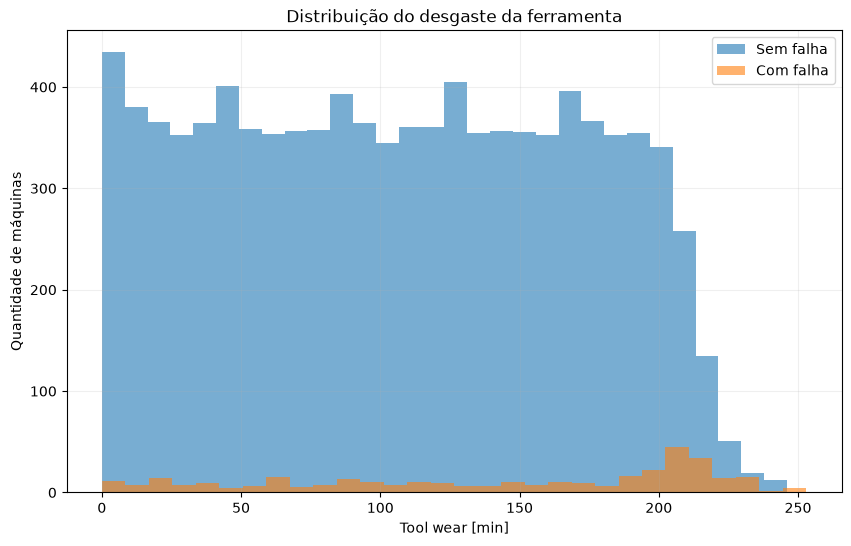

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df_clean[df_clean['Machine failure'] == 0]['Tool wear [min]'],
    bins=30,
    alpha=0.6,
    label='Sem falha'
)

plt.hist(
    df_clean[df_clean['Machine failure'] == 1]['Tool wear [min]'],
    bins=30,
    alpha=0.6,
    label='Com falha'
)

plt.xlabel('Tool wear [min]')
plt.ylabel('Quantidade de máquinas')
plt.title('Distribuição do desgaste da ferramenta')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

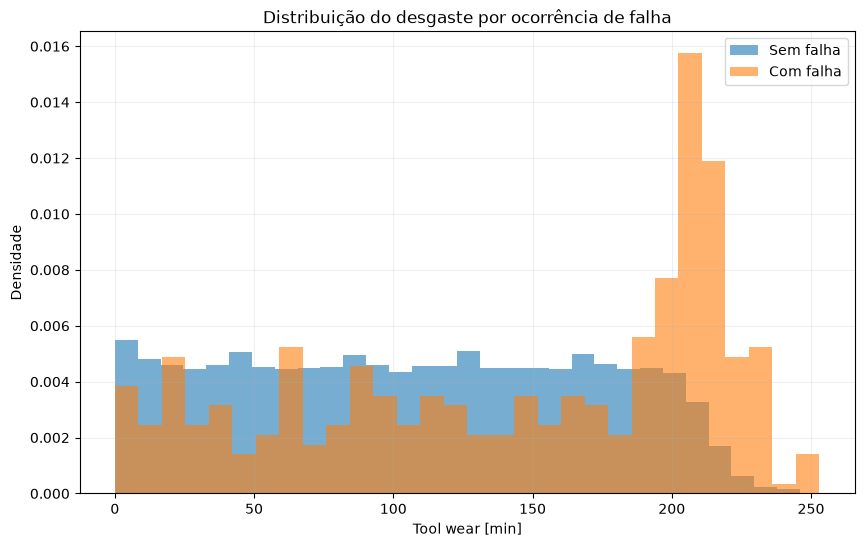

In [7]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_clean[df_clean['Machine failure'] == 0]['Tool wear [min]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Sem falha'
)

plt.hist(
    df_clean[df_clean['Machine failure'] == 1]['Tool wear [min]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Com falha'
)

plt.xlabel('Tool wear [min]')
plt.ylabel('Densidade')
plt.title('Distribuição do desgaste por ocorrência de falha')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

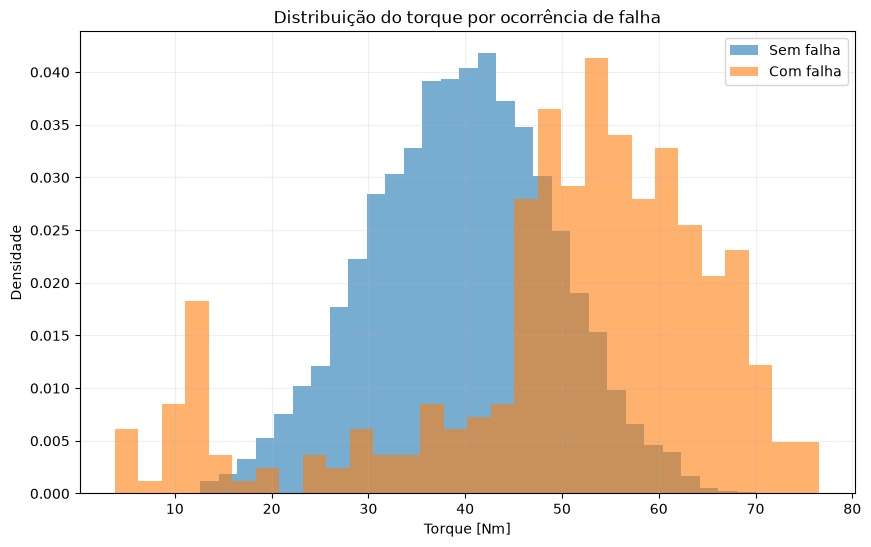

In [8]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_clean[df_clean['Machine failure'] == 0]['Torque [Nm]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Sem falha'
)

plt.hist(
    df_clean[df_clean['Machine failure'] == 1]['Torque [Nm]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Com falha'
)

plt.xlabel('Torque [Nm]')
plt.ylabel('Densidade')
plt.title('Distribuição do torque por ocorrência de falha')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

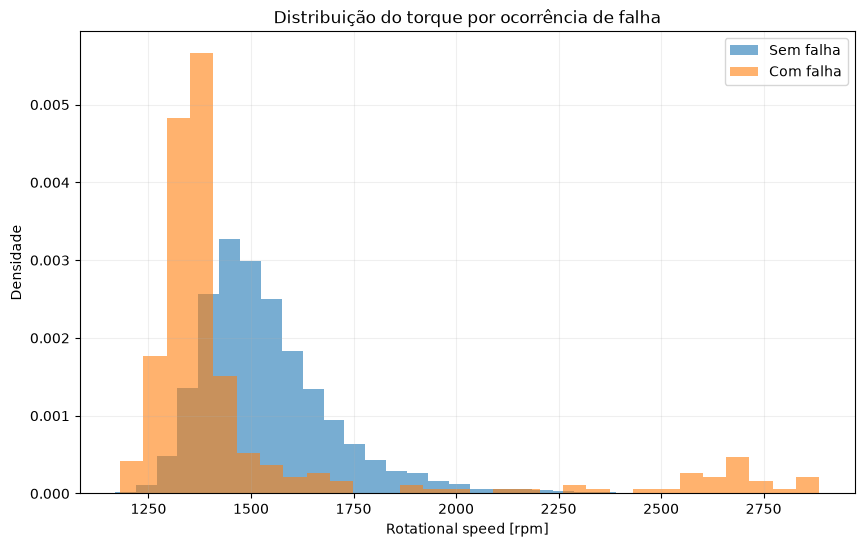

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_clean[df_clean['Machine failure'] == 0]['Rotational speed [rpm]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Sem falha'
)

plt.hist(
    df_clean[df_clean['Machine failure'] == 1]['Rotational speed [rpm]'],
    bins=30,
    density=True,
    alpha=0.6,
    label='Com falha'
)

plt.xlabel('Rotational speed [rpm]')
plt.ylabel('Densidade')
plt.title('Distribuição do torque por ocorrência de falha')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

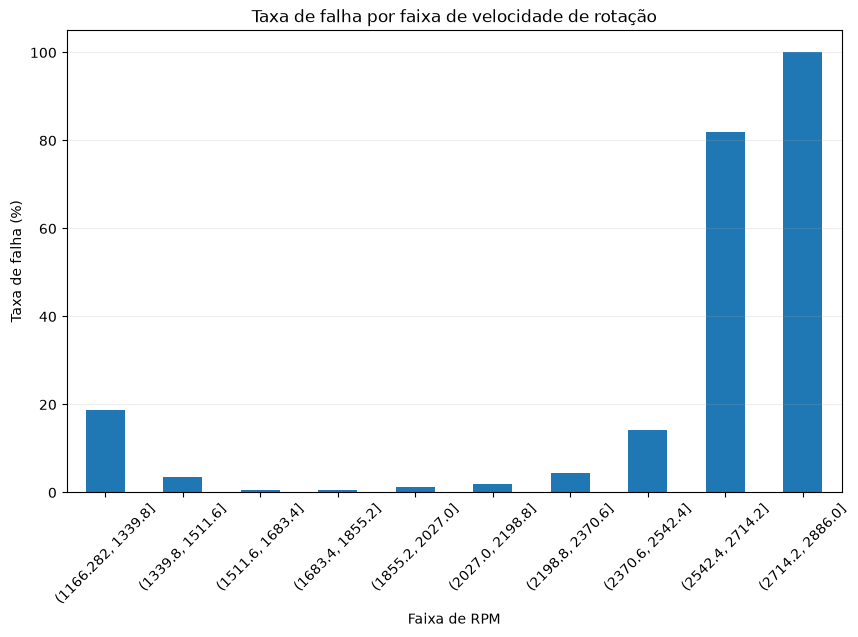

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df_rpm = df_clean.copy()

df_rpm['RPM faixa'] = pd.cut(
    df_rpm['Rotational speed [rpm]'],
    bins=10
)

failure_rate = df_rpm.groupby(
    'RPM faixa',
    observed=True
)['Machine failure'].mean() * 100

plt.figure(figsize=(10, 6))

failure_rate.plot(kind='bar')

plt.xlabel('Faixa de RPM')
plt.ylabel('Taxa de falha (%)')
plt.title('Taxa de falha por faixa de velocidade de rotação')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.2)

plt.show()

In [11]:
rpm_analysis = df_rpm.groupby(
    'RPM faixa',
    observed=True
)['Machine failure'].agg(['count', 'sum', 'mean'])

rpm_analysis['failure_rate_%'] = rpm_analysis['mean'] * 100

rpm_analysis

,count,sum,mean,failure_rate_%
RPM faixa,,,,
"(1166.282, 1339.8]",602,113,0.187708,18.770764
"(1339.8, 1511.6]",4650,168,0.036129,3.612903
"(1511.6, 1683.4]",3227,16,0.004958,0.495817
"(1683.4, 1855.2]",987,5,0.005066,0.506586
"(1855.2, 2027.0]",337,4,0.011869,1.186944
"(2027.0, 2198.8]",101,2,0.019802,1.980198
"(2198.8, 2370.6]",45,2,0.044444,4.444444
"(2370.6, 2542.4]",21,3,0.142857,14.285714
"(2542.4, 2714.2]",22,18,0.818182,81.818182


In [12]:
X = df_clean[[
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]]

y = df_clean['Machine failure']

In [13]:
X.shape
#10000 maquinas e 6 caracteristicas

(10000, 6)

In [14]:
X.shape
y.shape

(10000,)

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [16]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [17]:
categorical_features = ['Type']

numeric_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [19]:
X_train_encoded = preprocessor.fit_transform(X_train)

In [20]:
X_test_encoded = preprocessor.transform(X_test)

In [21]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(8000, 8)
(2000, 8)


In [22]:
from xgboost import XGBClassifier

model = XGBClassifier()

In [23]:
model.fit(X_train_encoded, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
y_pred = model.predict(X_test_encoded)

In [25]:
y_pred[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [26]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

cm

array([[1927,    5],
       [  19,   49]])

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [28]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9880


In [29]:
precision = precision_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")

Precision: 0.9074


In [30]:
recall = recall_score(y_test, y_pred)

print(f"Recall: {recall:.4f}")

Recall: 0.7206


In [31]:
f1 = f1_score(y_test, y_pred)

print(f"F1-score: {f1:.4f}")

F1-score: 0.8033


In [32]:
import shap

In [33]:
explainer = shap.TreeExplainer(model)

In [34]:
shap_values = explainer(X_test_encoded)

In [35]:
explainer = shap.TreeExplainer(model)

In [36]:
shap_values = explainer(X_test_encoded)

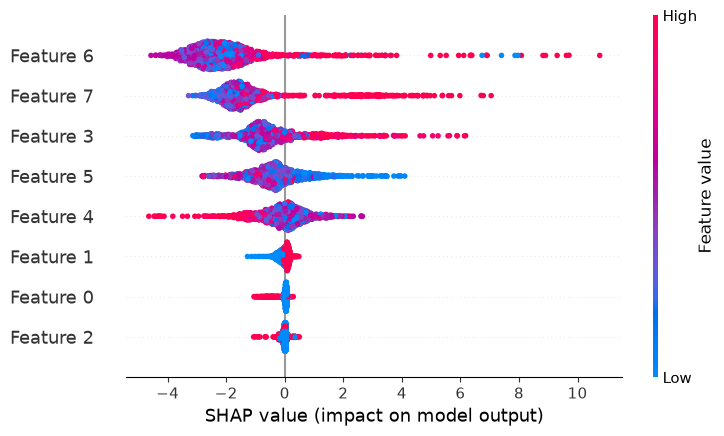

In [37]:
shap.plots.beeswarm(shap_values, max_display=8)

In [38]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['cat__Type_H' 'cat__Type_L' 'cat__Type_M'
 'remainder__Air temperature [K]' 'remainder__Process temperature [K]'
 'remainder__Rotational speed [rpm]' 'remainder__Torque [Nm]'
 'remainder__Tool wear [min]']


In [39]:
X_test_shap = pd.DataFrame(
    X_test_encoded,
    columns=feature_names
)

In [40]:
feature_names_safe = [
    'Type_H',
    'Type_L',
    'Type_M',
    'Air_temperature_K',
    'Process_temperature_K',
    'Rotational_speed_rpm',
    'Torque_Nm',
    'Tool_wear_min'
]

X_test_shap = pd.DataFrame(
    X_test_encoded,
    columns=feature_names_safe
)
shap_values = explainer(X_test_shap)

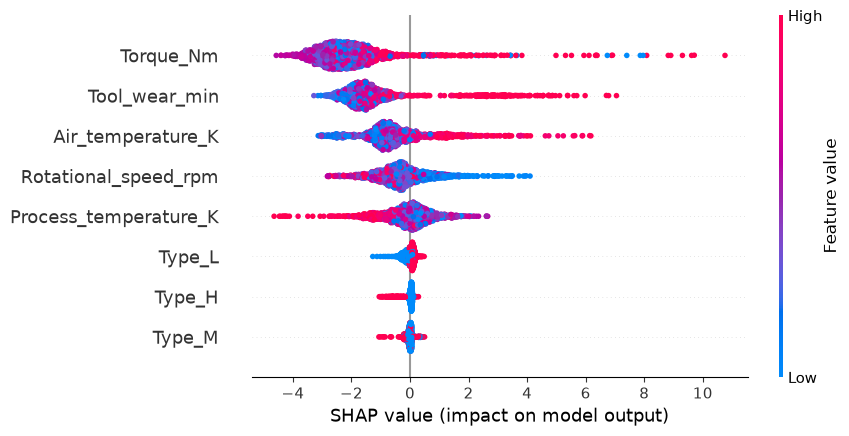

In [41]:
shap.plots.beeswarm(shap_values, max_display=8)